To do : 

implement R-score for default ps.SINDy parameters
- find out how ps.SINDy implements SLTSQ
Notes :
- if you want to implement an integrator yourself, you need to define a function that is parametrised by the selected coefficients and that returns a combination of all the library functions for each component.

Good to know : 
ps.SINDy location 
C:\\Users\\abdel\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\pysindy\\_core.py

Note : SINDy imports STLSQ from .optimizers

Essence of model.fit:
class SINDy(_BaseSINDy): 
        ....
        def fit(...):
        ...
        
        self.feature_names = feature_names

        x_dot = concat_sample_axis(x_dot)
        x = self.feature_library.fit_transform(x)
        x = SampleConcatter().fit_transform(x)
        self.optimizer.fit(x, x_dot)
        self._fit_shape()

        return self

Complicated code in stlsq.py , where's the actual optimization 'happening'/supposed to happen?

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from pysindy import SINDy
from pysindy.optimizers import STLSQ
import inspect
import time

In [4]:
dataframe = pd.read_csv("./lorenz_data.csv")
data = dataframe.to_numpy()
data_shape = data.shape

Maybe show the coefficients of the actual model for each sparsity threshold

In [107]:

def generate_models(thresholds):
    opts = [STLSQ(threshold=hyperparam) for hyperparam in thresholds]
    models = [SINDy(optimizer=opt) for opt in opts]
    return models


def generate(t,x,xdot,xnoise, models, m_range, initial_point):
# we use the default differentiation_method = FiniteDifference(axis=-2)
    print(f"Initial point : {initial_point}")
    Rsqs = []
    for i in range(0,m_range):
        model = models[i]
        model.fit(x,t,xdot,feature_names=['x','y','z'])
        coeffs0 = model.coefficients()
        sample_path0 = model.simulate(initial_point,t[1:1001])
        avg_groundtruth = np.mean(sample_path0[1:,:], axis=0)
        
        model.fit(xnoise,t,feature_names=['x','y','z'])
        coeffsnoise1 = model.coefficients()
        sample_path1 = model.simulate(initial_point,t[1:1001])
    
        
        SSE = np.sum(np.linalg.norm(sample_path0[1:,:]-sample_path1[1:,:]), axis=0)
        SST = np.sum(np.linalg.norm(sample_path0[1:,:]-avg_groundtruth), axis=0)
        Rsq = 1-(SSE/SST)

        print("Step: " + str(i))
        print(f"Threshold: {model.optimizer.threshold}" + " | ",f"R^2 {Rsq}")
        Rsqs.append(Rsq)
        
    return Rsqs, SSE, SST

In [84]:
t = data[:,0]
x = data[:,1:4]
xdot = data[:,4:]

gnoise = np.random.normal(0,1,data_shape)
xnoise = x + gnoise[:,1:4]
xdotnoise = xdot + gnoise[:,4:] # could be useful later, for now numerically differentiate xnoise with default

In [108]:
start_time = time.time()

np.random.seed(0)
initial_point = np.random.normal(0,1,3)
# default feature names are polynomials, see SINDy class core.py
# SINDy4Engineers (Tutorial 1-4 or 1-3) sweep : define the lambda values to sweep
thresholds = np.logspace(-16,-1,20)
m_range = len(thresholds)
models = generate_models(thresholds)
Rsqs, _,_ = generate(t,x,xdot,xnoise, models, m_range, initial_point)

end_time = time.time()
print(f"Generation time: {end_time-start_time} seconds")

Initial point : [1.76405235 0.40015721 0.97873798]
Step: 0
Threshold: 1e-16 |  R^2 -0.9114743119807434
Step: 1
Threshold: 6.158482110660255e-16 |  R^2 -0.9114743119807434
Step: 2
Threshold: 3.7926901907322535e-15 |  R^2 -0.9114743119807434
Step: 3
Threshold: 2.3357214690901213e-14 |  R^2 -0.9114743119807434
Step: 4
Threshold: 1.438449888287666e-13 |  R^2 -0.9114743119807434
Step: 5
Threshold: 8.858667904100832e-13 |  R^2 -0.9114743119807434
Step: 6
Threshold: 5.455594781168514e-12 |  R^2 -0.9114743119807434
Step: 7
Threshold: 3.359818286283788e-11 |  R^2 -0.9114743119807434
Step: 8
Threshold: 2.0691380811147902e-10 |  R^2 -0.9114743119807434
Step: 9
Threshold: 1.2742749857031322e-09 |  R^2 -0.9114743119807434
Step: 10
Threshold: 7.847599703514623e-09 |  R^2 -0.9114743119807434
Step: 11
Threshold: 4.832930238571752e-08 |  R^2 -0.9114743119769135
Step: 12
Threshold: 2.976351441631313e-07 |  R^2 -0.9114743119606303
Step: 13
Threshold: 1.8329807108324375e-06 |  R^2 -0.9114743119783406
Step

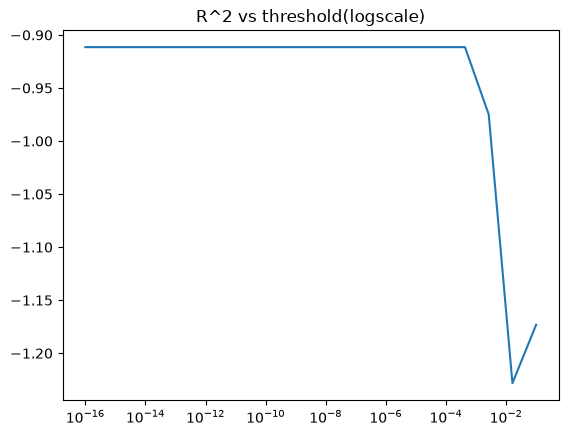

In [120]:
plt.plot(thresholds[:],Rsqs)
plt.title("R^2 vs threshold(logscale)")
plt.xscale('log')
plt.show()
# saves only blank pngs, weird : plt.savefig(f"R^2-threshold-plots/R^2-threshold(logscale)-{time.strftime("%Y%m%d-%H%M%S")}.png")

In [119]:
xdeviations_dataframe = pd.DataFrame(data=xnoise-x)
print(xdeviations_dataframe)
xdeviations_dataframe.to_csv(f"R^2-threshold-data/xdeviations_{time.strftime("%Y%m%d-%H%M%S")}.csv")
pd.DataFrame(data=xnoise).to_csv(f"R^2-threshold-data/xnoise_{time.strftime("%Y%m%d-%H%M%S")}.csv")

              0         1         2
0     -0.599483  1.513384  0.240293
1     -0.702424  1.024180 -0.585836
2     -2.108976  2.054676 -0.523596
3      1.304651 -0.254152  1.295160
4      0.869661  1.086157  1.880793
...         ...       ...       ...
9996  -1.632933 -1.269181  0.818345
9997   1.183869  0.253932  0.466415
9998   1.317509 -0.674085 -0.137820
9999  -0.589980  0.637124 -0.950170
10000 -0.906924  0.211237 -0.596004

[10001 rows x 3 columns]


First succesful run : i from 1 to 10 gives an output of all 1.0 for Rsq. looks like R-squared is a poor measure or something is wrong with the code. All models have "perfect" fit, which is unlikely.

Second run, now with i from 1 to 25, the output for Rsq is only 1's

Maybe the added noise is insignificant?
- Turns the averaging over the sample path from the correct Lorenz system was incorrect, as well as the selection of the other sample paths
- First [0,0,1] was chosen as initial point.. which resulted in negative R-squared to the order of -600. Using [1,1,1] changed this behavior to numbers like 0.90... , 0.88... ...
- Note : in the actual lorenz system, choosing [0,0,1] initially purely leads to dynamics on z : the z-axis is an invariant set.

We need to compare the actual model with the predicted model(s)
For each model, we have the information we need from the coefficients and the feature library. 
We want to numerically integrate these models to see how they compare to each other.
Choose some point x,y,z and take it as starting value.

Output A : random initial position (should use np.random.seed(123) from now on)
- note, possible changes : compare coordinate vectors instead of individual coordinates (the output is only for the x[0] = x coordinate).
- compare the first few points on the forward-time orbit, instead of the points at the "end" of the orbit (i.e. after many time-steps).

CPU times: total: 0 ns
Wall time: 11.4 μs
1e-19 -3.6300202803827526
3.25702065565977e-19 -3.6300202803827526
1.0608183551394482e-18 -3.6300202803827526
3.4551072945922325e-18 -3.6300202803827526
1.1253355826007645e-17 -3.6300202803827526
3.6652412370796113e-17 -3.6300202803827526
1.1937766417144357e-16 -3.6300202803827526
3.888155180308085e-16 -3.6300202803827526
1.2663801734674023e-15 -3.6300202803827526
4.1246263829013476e-15 -3.6300202803827526
1.3433993325988988e-14 -3.6300202803827526
4.37547937507418e-14 -3.6300202803827526
1.4251026703029963e-13 -3.6300202803827526
4.641588833612772e-13 -3.6300202803827526
1.51177507061566e-12 -3.6300202803827526
4.923882631706732e-12 -3.6300202803827526
1.6037187437513276e-11 -3.6300202803827526
5.2233450742668324e-11 -3.6300202803827526
1.7012542798525856e-10 -3.6300202803827526
5.54102033000948e-10 -3.6300202803827526
1.8047217668271665e-09 -3.6300202803827526
5.8780160722749e-09 -3.6300202803827526
1.9144819761699535e-08 -3.6300202803827526
6.235507341273899e-08 -3.630020280393749
2.0309176209047306e-07 -3.6300202803801502
6.614740641230132e-07 -3.6300202803792647
2.154434690031878e-06 -3.6300202803792647
7.017038286703808e-06 -3.630020280391909
2.2854638641349838e-05 -3.630020280391909
7.443803013251666e-05 -3.630020280391909
0.0002424462017082321 -3.630020280391909
0.0007896522868499701 -3.630020280391909
0.0025719138090593363 -3.6565872043752163
0.008376776400682856 -3.8250158695245435
0.027283333764867582 -6.906818509152042
0.08886238162743407 -6.617623901511779
0.289426612471674 -4.952189845009328
0.9426684551178777 -3.87434046270669
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (3.0702906297578374) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (3.0702906297578374) and eliminated all coefficients
  warnings.warn(
3.0702906297578374 -221.4277314235846
10.0 1.0
CPU times: total: 0 ns
Wall time: 8.82 μs
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (3.0702906297578374) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (10.0) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (10.0) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (10.0) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (10.0) and eliminated all coefficients
  warnings.warn(
C:\Users\abdel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (10.0) and eliminated all coefficients
  warnings.warn(